# Monthly revenue and seasonality

How does revenue change month by month, and is there a seasonal pattern?

In [3]:
import duckdb
con = duckdb.connect("../data/retail.duckdb", read_only=True)

In [8]:
con.sql("SELECT * FROM clean_sales LIMIT 10").show()

┌─────────┬────────────┬───────────────────────────────────┬──────────┬─────────────────────┬────────┬─────────────┬────────────────┬─────────┐
│ invoice │ stock_code │            description            │ quantity │    invoice_date     │ price  │ customer_id │    country     │ revenue │
│ varchar │  varchar   │              varchar              │  int64   │      timestamp      │ double │   varchar   │    varchar     │ double  │
├─────────┼────────────┼───────────────────────────────────┼──────────┼─────────────────────┼────────┼─────────────┼────────────────┼─────────┤
│ 501138  │ 84456      │ SET OF 3 RABBIT EGG EASTER        │        1 │ 2010-03-14 12:05:00 │   0.85 │ 14532       │ United Kingdom │    0.85 │
│ 501141  │ 21445      │ 12 PINK ROSE PEG PLACE SETTINGS   │        2 │ 2010-03-14 12:18:00 │   1.25 │ 16255       │ United Kingdom │     2.5 │
│ 501141  │ 21121      │ SET/10 RED SPOTTY PARTY CANDLES   │        4 │ 2010-03-14 12:18:00 │   1.25 │ 16255       │ United Kingdom │   

In [17]:
con.sql("""SELECT DATE_TRUNC('month', invoice_date) AS month,
            ROUND(SUM(revenue), 2) AS revenue,
            COUNT(DISTINCT invoice) AS orders,
            COUNT(DISTINCT customer_id) AS customers
        FROM clean_sales
        GROUP BY month
        ORDER BY revenue DESC""").show(max_rows=30)

┌─────────────────────┬────────────┬────────┬───────────┐
│        month        │  revenue   │ orders │ customers │
│      timestamp      │   double   │ int64  │   int64   │
├─────────────────────┼────────────┼────────┼───────────┤
│ 2011-11-01 00:00:00 │ 1452115.98 │   2751 │      1660 │
│ 2010-11-01 00:00:00 │ 1429700.78 │   2719 │      1606 │
│ 2011-10-01 00:00:00 │ 1103314.25 │   2005 │      1361 │
│ 2010-10-01 00:00:00 │ 1094435.98 │   2244 │      1492 │
│ 2011-09-01 00:00:00 │ 1028320.38 │   1818 │      1259 │
│ 2010-09-01 00:00:00 │  869243.12 │   1789 │      1136 │
│ 2009-12-01 00:00:00 │  797901.16 │   1666 │       951 │
│ 2010-12-01 00:00:00 │  775638.36 │   1550 │       884 │
│ 2010-03-01 00:00:00 │  761705.98 │   1647 │      1051 │
│ 2011-05-01 00:00:00 │   739953.0 │   1668 │      1054 │
│ 2011-06-01 00:00:00 │  737558.98 │   1525 │       990 │
│ 2011-08-01 00:00:00 │   724216.5 │   1339 │       933 │
│ 2010-06-01 00:00:00 │  696583.19 │   1612 │      1034 │
│ 2011-03-01 0

-**Peak:** Table shows that the peak of sales is on the month of November in 2010 and 2011, with November 2011 having the highest with £1,452,115.98 in total revenue. This is likely due to wholesale customers stocking up for upcoming Christmas. 

-**Low**: The month that was weakest in revenue is on February of 2011 with only £507,799.87 in revenue, whereas the February 2010 is also one of the weakest sales. It is noticeable that February is consistently the weakest month as holidays have already finished. 

-**December 2011 caveat**: It looks like a big drop because the data covers only 9 days of that month so it does not capture a whole month's sale and must not be compared with other full months. 

-**Growth**: Total revenue grew by 5.61% comparing Sep-Nov 2011 to Sep-Nov 2010, while Nov 2011 was only 1.57% higher than Nov 2010. It's the season where revenue is the biggest whereas they are top 6 months of biggest revenue within the data duration.

In [18]:
con.sql("""SELECT DATE_TRUNC('month', invoice_date) AS month,
            ROUND(SUM(revenue), 2) AS revenue,
            COUNT(DISTINCT invoice) AS orders,
            COUNT(DISTINCT customer_id) AS customers
        FROM clean_sales
        GROUP BY month
        ORDER BY month""").show(max_rows=30)

┌─────────────────────┬────────────┬────────┬───────────┐
│        month        │  revenue   │ orders │ customers │
│      timestamp      │   double   │ int64  │   int64   │
├─────────────────────┼────────────┼────────┼───────────┤
│ 2009-12-01 00:00:00 │  797901.16 │   1666 │       951 │
│ 2010-01-01 00:00:00 │  612297.42 │   1049 │       701 │
│ 2010-02-01 00:00:00 │  537909.67 │   1189 │       771 │
│ 2010-03-01 00:00:00 │  761705.98 │   1647 │      1051 │
│ 2010-04-01 00:00:00 │  646340.93 │   1435 │       939 │
│ 2010-05-01 00:00:00 │  643492.03 │   1484 │       965 │
│ 2010-06-01 00:00:00 │  696583.19 │   1612 │      1034 │
│ 2010-07-01 00:00:00 │  632994.32 │   1507 │       924 │
│ 2010-08-01 00:00:00 │  674037.72 │   1402 │       910 │
│ 2010-09-01 00:00:00 │  869243.12 │   1789 │      1136 │
│ 2010-10-01 00:00:00 │ 1094435.98 │   2244 │      1492 │
│ 2010-11-01 00:00:00 │ 1429700.78 │   2719 │      1606 │
│ 2010-12-01 00:00:00 │  775638.36 │   1550 │       884 │
│ 2011-01-01 0

In [33]:
monthly = con.sql("""SELECT DATE_TRUNC('month', invoice_date) AS month,
            ROUND(SUM(revenue), 2) AS revenue,
            COUNT(DISTINCT invoice) AS orders,
            COUNT(DISTINCT customer_id) AS customers
        FROM clean_sales
        WHERE invoice_date < '2011-12-01'
        GROUP BY month
        ORDER BY month""").df()
monthly.head()

,month,revenue,orders,customers
0,2009-12-01,797901.16,1666,951
1,2010-01-01,612297.42,1049,701
2,2010-02-01,537909.67,1189,771
3,2010-03-01,761705.98,1647,1051
4,2010-04-01,646340.93,1435,939


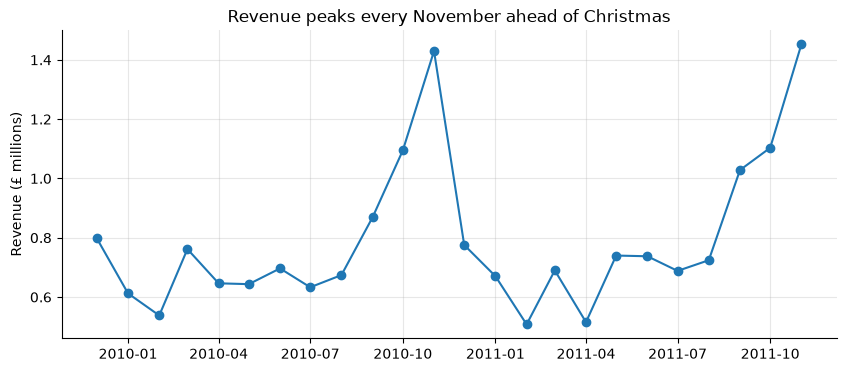

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(monthly['month'], monthly['revenue']/1000000, marker="o")

ax.set_title("Revenue peaks every November ahead of Christmas")
ax.set_ylabel("Revenue (£ millions)")

ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.savefig("../images/monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

Dec 2011 excluded: the data ends on 9 Dec 2011, so it is a partial month.